# **Simulating the ODEs and $\mathcal{R}_0$ with `simulate()`**

$\mathcal{R}_0$ is a threshold: if $\mathcal{R}_0 < 1$ an infection introduced near the disease-free equilibrium (DFE) dies out, and if $\mathcal{R}_0 > 1$ it invades. `model.simulate()` integrates the ODE system to show this behavior:

* The parameters given in `values={...}` are **fixed**. The others are **drawn at random**: log-uniform in `default_range` (by default $[0.01, 1]$), or in their own range with `ranges={...}`.
* `n_runs` produces several simulations, and `R0_range` keeps only the draws with $\mathcal{R}_0$ in a range, for example `(1, None)` for $\mathcal{R}_0 > 1$.
* By default, the uninfected compartments start at the DFE and the infected ones at a small perturbation (`perturbation`, 1 % of the total). Initial conditions are given with `initial={...}`.
* Each simulation stores its parameters, its initial condition, its $\mathcal{R}_0$ and its DFE.

Plots are edited with the arguments of `plot()` and `plot_phase()`:

| Argument | Purpose |
|---|---|
| `variables` | variables to plot |
| `title`, `titles` | title (`"{R0}"` is replaced by its value) and title of each panel |
| `xlabel`, `ylabel` | axis labels (LaTeX between `$...$` is allowed) |
| `labels`, `colors`, `linestyles` | per variable: dictionary, list or a single value |
| `linewidth`, `alpha` | line width and opacity |
| `legend`, `legend_kw` | show or hide the legend, its location and other options |
| `figsize`, `subplots`, `ncols` | figure size and one panel per variable |
| `logy`, `logx`, `xlim`, `ylim`, `grid` | scales, limits and grid |
| `color_by_R0` | color each simulation by $\mathcal{R}_0 < 1$ or $\mathcal{R}_0 > 1$ |
| `show_dfe` | horizontal line at the DFE value |
| `ax` | draw on existing axes, to compare scenarios |
| `save`, `dpi` | save the figure (here, in `outputs/`) |

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Yvan-BM-Git/pyR0compute/blob/main/examples/06_simulations.ipynb)

In [1]:
%pip install pyR0compute                      # Install pyR0compute from PyPI

In [2]:
import os                                     # Folder for the figures
import warnings                               # Warnings of the library
import numpy as np                            # Numerical computation
import sympy as sp                            # Symbolic computation
import matplotlib.pyplot as plt               # Plots
from pyr0compute import R0Model               # Main class of the library
from pyr0compute.simulation import PALETTE    # Colors of the library (fixed order)

os.makedirs("outputs", exist_ok=True)         # Figures are saved in outputs/

## 1. SIR with vital dynamics: $\mathcal{R}_0 < 1$ versus $\mathcal{R}_0 > 1$

$$
\dot S = \Lambda - \beta S I - \mu S, \qquad
\dot I = \beta S I - (\gamma + \mu) I, \qquad
\dot R = \gamma I - \mu R, \qquad
\mathcal{R}_0 = \frac{\Lambda\beta}{\mu(\gamma+\mu)}.
$$

With $\mathcal{R}_0 > 1$ the solution converges to the endemic equilibrium $S^\dagger = (\gamma+\mu)/\beta$, $I^\dagger = \Lambda/(\gamma+\mu) - \mu/\beta$. The dashed lines (`show_dfe=True`) mark the DFE $S^* = \Lambda/\mu$.

In [3]:
sir = R0Model('''
    dS/dt = Lambda - beta*S*I - mu*S
    dI/dt = beta*S*I - (gamma + mu)*I
    dR/dt = gamma*I - mu*R
''', infected=["I"])
print("R0 =", sir.R0)

base = dict(Lambda=10, mu=0.1, gamma=0.5)          # fixed parameters
low = sir.simulate((0, 200), values=dict(base, beta=0.002))
high = sir.simulate((0, 200), values=dict(base, beta=0.01))
print(low)
print(high)
print("Initial condition (DFE + perturbation):", high.initial)

beta = 0.01
print(f"\nFinal state with R0 > 1: S = {high.final()['S']:.4f}, I = {high.final()['I']:.4f}")
print(f"Endemic equilibrium:     S = {(base['gamma'] + base['mu']) / beta:.4f}, "
      f"I = {base['Lambda'] / (base['gamma'] + base['mu']) - base['mu'] / beta:.4f}")

R0 = Lambda*beta/(mu*(gamma + mu))


SimulationResult(1 run, R0 = 0.3333, t in [0, 200])
SimulationResult(1 run, R0 = 1.667, t in [0, 200])
Initial condition (DFE + perturbation): {'S': 100.0, 'I': 1.0, 'R': 0.0}

Final state with R0 > 1: S = 60.0000, I = 6.6667
Endemic equilibrium:     S = 60.0000, I = 6.6667


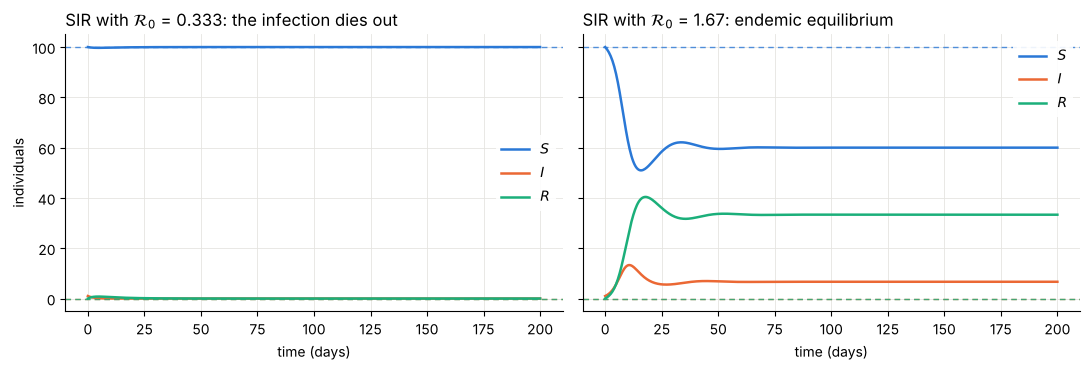

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
low.plot(ax=axes[0], title=r"SIR with $\mathcal{R}_0$ = {R0}: the infection dies out", show_dfe=True,
         xlabel="time (days)", ylabel="individuals")
high.plot(ax=axes[1], title=r"SIR with $\mathcal{R}_0$ = {R0}: endemic equilibrium", show_dfe=True,
          xlabel="time (days)")
fig.tight_layout()
fig.savefig("outputs/06_sir_R0_below_and_above_1.png", dpi=200, bbox_inches="tight")

### Customizing a figure

Selected variables, names, colors, line styles, logarithmic scale, limits, legend and size:

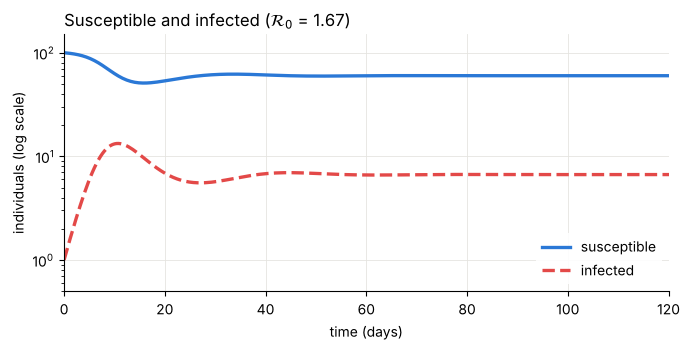

In [5]:
high.plot(["S", "I"],
          title=r"Susceptible and infected ($\mathcal{R}_0$ = {R0})",
          xlabel="time (days)", ylabel="individuals (log scale)",
          labels={"S": "susceptible", "I": "infected"},
          colors={"S": PALETTE[0], "I": PALETTE[7]},
          linestyles={"S": "-", "I": "--"}, linewidth=2.4,
          logy=True, ylim=(0.5, 150), xlim=(0, 120),
          legend="lower right", figsize=(7, 3.6),
          save="outputs/06_sir_custom.png");

## 2. Random parameters by default

Without `values`, all parameters are drawn at random. `seed` makes the draw reproducible, and `summary()` shows the values used and the $\mathcal{R}_0$ of each simulation.

In [6]:
rand = sir.simulate((0, 100), n_runs=4, seed=7)
print(rand)
rand.summary()

SimulationResult(4 runs, R0 < 1 in 2, R0 > 1 in 2, t in [0, 100])


,R0,Lambda,beta,gamma,mu
run,,,,,
0,10.226040,0.177906,0.622913,0.355936,0.028211
1,0.112851,0.039841,0.558608,0.010245,0.438992
2,12.301916,0.392770,0.086272,0.040371,0.036046
3,0.085324,0.032340,0.077652,0.102117,0.127937


## 3. Fixed and random parameters: an ensemble of simulations

We fix $\Lambda$, $\mu$ and $\gamma$, and draw $\beta$ in $[0.001, 0.02]$. Each simulation is colored by its $\mathcal{R}_0$ (`color_by_R0`, on by default with several runs). Those with $\mathcal{R}_0 < 1$ return to the DFE; those with $\mathcal{R}_0 > 1$ move away from it towards an endemic equilibrium.

SimulationResult(40 runs, R0 < 1 in 26, R0 > 1 in 14, t in [0, 200])


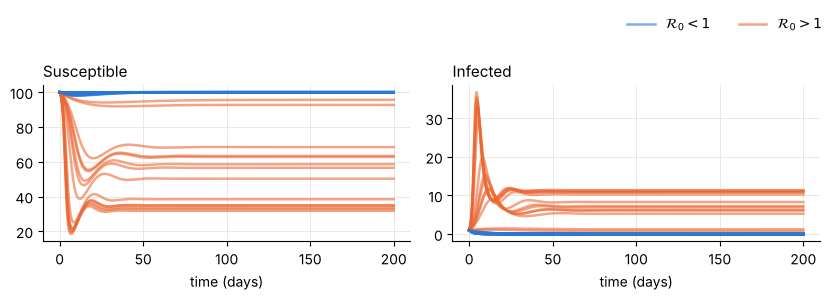

In [7]:
ensemble = sir.simulate((0, 200), values=base, ranges={"beta": (0.001, 0.02)}, n_runs=40, seed=1)
print(ensemble)
ensemble.plot(["S", "I"], subplots=True, ncols=2, xlabel="time (days)",
              titles={"S": "Susceptible", "I": "Infected"},
              save="outputs/06_sir_ensemble_by_R0.png");

The phase plane shows the same: from the DFE (✕), the trajectories with $\mathcal{R}_0 > 1$ spiral towards an endemic equilibrium. With a larger `n_points` the curves look smoother.

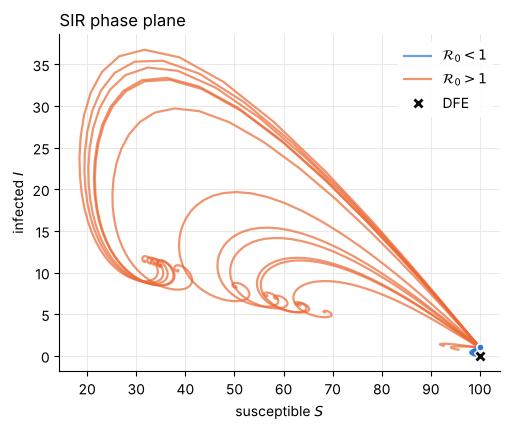

In [8]:
ensemble.plot_phase("S", "I", title="SIR phase plane", xlabel="susceptible $S$",
                    ylabel="infected $I$", save="outputs/06_sir_phase_plane.png");

### Only $\mathcal{R}_0 > 1$ or only $\mathcal{R}_0 < 1$

`R0_range` keeps only the draws that satisfy the condition.

R0 > 1: [4.03 1.74 2.88 2.18 1.5  2.29 1.98 7.34 2.41 1.23 5.44 3.46 6.2  1.05
 2.51]
R0 < 1: [0.46 0.54 0.24 0.35 0.21 0.49 0.3  0.91 0.87 0.77 0.35 0.65 0.58 0.25
 0.25]


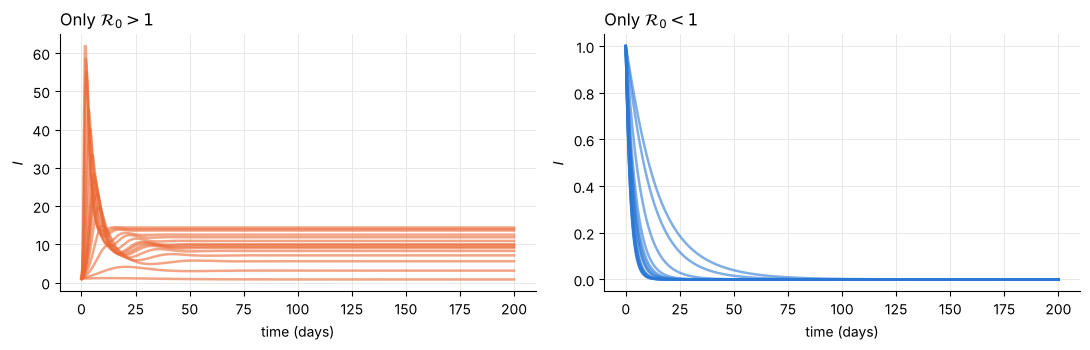

In [9]:
above = sir.simulate((0, 200), values=base, ranges={"beta": (0.001, 0.05)}, R0_range=(1, None),
                     n_runs=15, seed=2)
below = sir.simulate((0, 200), values=base, ranges={"beta": (0.001, 0.05)}, R0_range=(None, 1),
                     n_runs=15, seed=2)
print("R0 > 1:", np.round(above.R0_values, 2))
print("R0 < 1:", np.round(below.R0_values, 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
above.plot("I", ax=axes[0], title=r"Only $\mathcal{R}_0 > 1$", xlabel="time (days)", legend=False)
below.plot("I", ax=axes[1], title=r"Only $\mathcal{R}_0 < 1$", xlabel="time (days)", legend=False)
fig.tight_layout()
fig.savefig("outputs/06_sir_R0_range.png", dpi=200, bbox_inches="tight")

## 4. Transcritical bifurcation at $\mathcal{R}_0 = 1$

For each $\beta$ we simulate up to steady state and plot the final $I$ against $\mathcal{R}_0$. For $\mathcal{R}_0 \le 1$ the only stable equilibrium is the DFE ($I = 0$); for $\mathcal{R}_0 > 1$ it is the endemic one, $I^\dagger = \frac{\Lambda}{\gamma+\mu}\left(1 - \frac{1}{\mathcal{R}_0}\right)$.

Largest difference from theory: 1.8030021919912542e-13


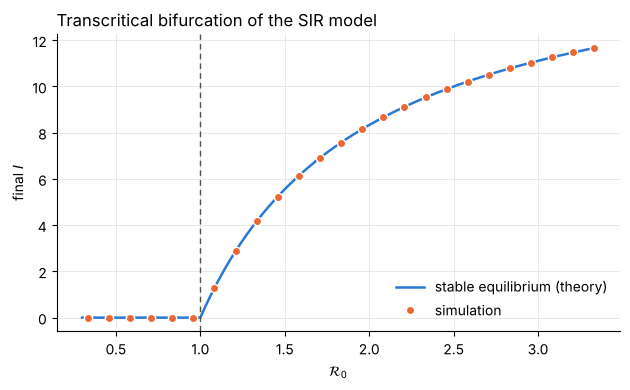

In [10]:
betas = np.linspace(0.002, 0.02, 25)
R0s, I_final = [], []
for b in betas:
    r = sir.simulate((0, 2000), values=dict(base, beta=b), n_points=200)
    R0s.append(r.R0)
    I_final.append(r.final()["I"])
R0s, I_final = np.array(R0s), np.array(I_final)

curve = np.linspace(0.3, R0s.max(), 300)
theory = np.where(curve > 1, base["Lambda"] / (base["gamma"] + base["mu"]) * (1 - 1 / curve), 0)

fig, ax = plt.subplots(figsize=(6.4, 4))
ax.plot(curve, theory, color=PALETTE[0], linewidth=1.8, label="stable equilibrium (theory)")
ax.plot(R0s, I_final, "o", color=PALETTE[1], markersize=6, markeredgecolor="white", label="simulation")
ax.axvline(1, color="#52514e", linewidth=1, linestyle=(0, (4, 3)))
ax.set_xlabel(r"$\mathcal{R}_0$")
ax.set_ylabel(r"final $I$")
ax.set_title("Transcritical bifurcation of the SIR model", loc="left")
ax.grid(True, color="#e5e4e0", linewidth=0.6)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("outputs/06_sir_transcritical_bifurcation.png", dpi=200, bbox_inches="tight")
print("Largest difference from theory:", np.max(np.abs(I_final - np.where(R0s > 1, base["Lambda"] / 0.6 * (1 - 1 / R0s), 0))))

### Near the threshold: slow convergence

Near the DFE, $\dot I \approx (\gamma+\mu)(\mathcal{R}_0 - 1)\, I$. With $\mathcal{R}_0 < 1$, $I$ decays exponentially at rate $(\gamma+\mu)(1 - \mathcal{R}_0)$: on a logarithmic scale it is a straight line, flatter the closer $\mathcal{R}_0$ is to 1. With $\mathcal{R}_0 > 1$, the endemic level $I^\dagger \propto 1 - 1/\mathcal{R}_0$ also tends to 0 as $\mathcal{R}_0 \to 1$.

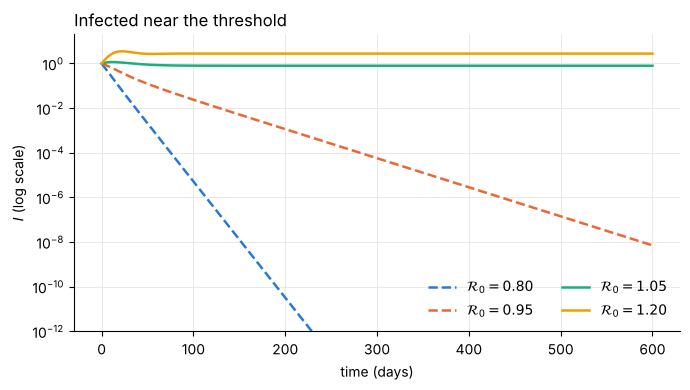

In [11]:
fig, ax = plt.subplots(figsize=(7, 4))
for k, R0_target in enumerate([0.8, 0.95, 1.05, 1.2]):
    b = R0_target * base["mu"] * (base["gamma"] + base["mu"]) / base["Lambda"]
    r = sir.simulate((0, 600), values=dict(base, beta=b))
    r.plot("I", ax=ax, colors=PALETTE[k], labels=rf"$\mathcal{{R}}_0 = {r.R0:.2f}$",
           linestyles="-" if r.R0 > 1 else "--", logy=True, ylim=(1e-12, 20), title="Infected near the threshold",
           xlabel="time (days)", ylabel="$I$ (log scale)", legend=False)
ax.legend(frameon=False, ncol=2)
fig.savefig("outputs/06_sir_near_threshold.png", dpi=200, bbox_inches="tight")

## 5. SEIR with vaccination: comparing scenarios on the same axes

A fraction $p$ of newborns is vaccinated ($W$):
$$
\dot S = (1-p)\Lambda - \beta S I - \mu S, \quad \dot W = p\Lambda - \mu W, \quad
\dot E = \beta S I - (\sigma+\mu) E, \quad \dot I = \sigma E - (\gamma+\mu) I, \quad \dot R = \gamma I - \mu R.
$$
$\mathcal{R}_0(p) = (1-p)\,\mathcal{R}_0(0)$, so the critical coverage is $p_c = 1 - 1/\mathcal{R}_0(0)$.

R0 = -Lambda*beta*sigma*(p - 1)/(mu*(gamma + mu)*(mu + sigma))
R0 without vaccination = 7.576; critical coverage p_c = 0.868


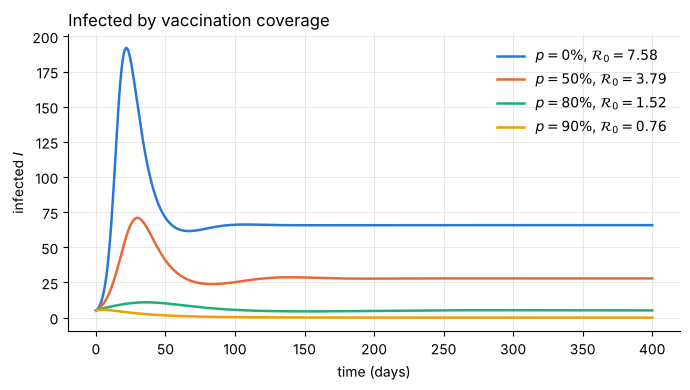

In [12]:
vaccine = R0Model('''
    dS/dt = (1 - p)*Lambda - beta*S*I - mu*S
    dW/dt = p*Lambda - mu*W
    dE/dt = beta*S*I - (sigma + mu)*E
    dI/dt = sigma*E - (gamma + mu)*I
    dR/dt = gamma*I - mu*R
''', infected=["E", "I"])
print("R0 =", sp.factor(vaccine.R0))

v = dict(Lambda=10, beta=0.002, mu=0.02, sigma=0.2, gamma=0.1)
R0_novax = vaccine.R0_numeric(dict(v, p=0))
print(f"R0 without vaccination = {R0_novax:.3f}; critical coverage p_c = {1 - 1 / R0_novax:.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
for k, p in enumerate([0.0, 0.5, 0.8, 0.9]):
    r = vaccine.simulate((0, 400), values=dict(v, p=p))
    r.plot("I", ax=ax, colors=PALETTE[k], labels=rf"$p = {p:.0%}$, $\mathcal{{R}}_0 = {r.R0:.2f}$".replace("%", r"\%"),
           title="Infected by vaccination coverage", xlabel="time (days)",
           ylabel="infected $I$", legend=False)
ax.legend(frameon=False)
fig.savefig("outputs/06_seir_vaccination.png", dpi=200, bbox_inches="tight")

## 6. Within-host model with target cells, infected cells and virus

$$
\dot T = s - dT - \beta T V, \quad \dot I = \beta T V - \delta I, \quad \dot V = pI - cV, \qquad
\mathcal{R}_0 = \frac{\beta p s}{c\, d\, \delta}.
$$

With $\mathcal{R}_0 = 2$ a chronic infection establishes itself and with $\mathcal{R}_0 = 0.5$ the virus is cleared. The viral load is better seen on a logarithmic scale.

R0 = beta*p*s/(c*d*delta)


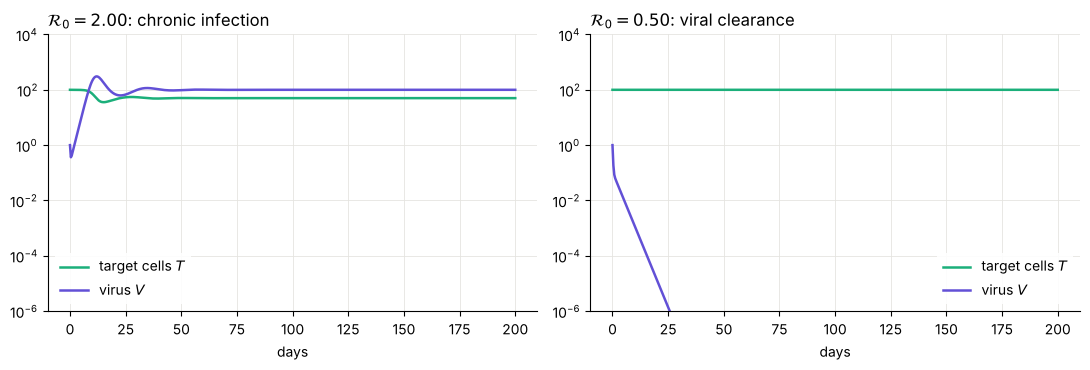

In [13]:
tiv = R0Model('''
    dT/dt = s - d*T - beta*T*V
    dI/dt = beta*T*V - delta*I
    dV/dt = p*I - c*V
''', infected=["I", "V"])
print("R0 =", tiv.R0)

vals = dict(s=10, d=0.1, beta=1e-3, delta=1, c=5)
chronic = tiv.simulate((0, 200), values=dict(vals, p=100), initial={"T": 100, "I": 0, "V": 1})
cleared = tiv.simulate((0, 200), values=dict(vals, p=25), initial={"T": 100, "I": 0, "V": 1})

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, r, txt in [(axes[0], chronic, "chronic infection"), (axes[1], cleared, "viral clearance")]:
    r.plot(["T", "V"], ax=ax, title=rf"$\mathcal{{R}}_0 = {r.R0:.2f}$: {txt}", logy=True, ylim=(1e-6, 1e4),
           labels={"T": "target cells $T$", "V": "virus $V$"}, colors={"T": PALETTE[2], "V": PALETTE[6]},
           xlabel="days")
fig.savefig("outputs/06_tiv_viral_load.png", dpi=200, bbox_inches="tight")

## 7. T-helper lymphocyte model (Cuesta-Herrera et al., 2025)

With the values of Table 1 of the paper, $\mathcal{R}_0^* = 6030$ (Figure 3a), and with those of Figure 3c, $\mathcal{R}_0^* = 19.89$. If the baseline production of helper T lymphocytes is high ($b = 3\times 10^{7}$), then $T_{h0} = b/c$ increases the removal of infected cells and virus, and $\mathcal{R}_0^* < 1$. We start from the DFE with 10 virus particles.

Table 1          R0* = 6030.3030   final V = 9.236e+08
Figure 3c        R0* =   19.8920   final V = 3.525e+06


High baseline Th R0* =    0.5419   final V = 2.106e-25


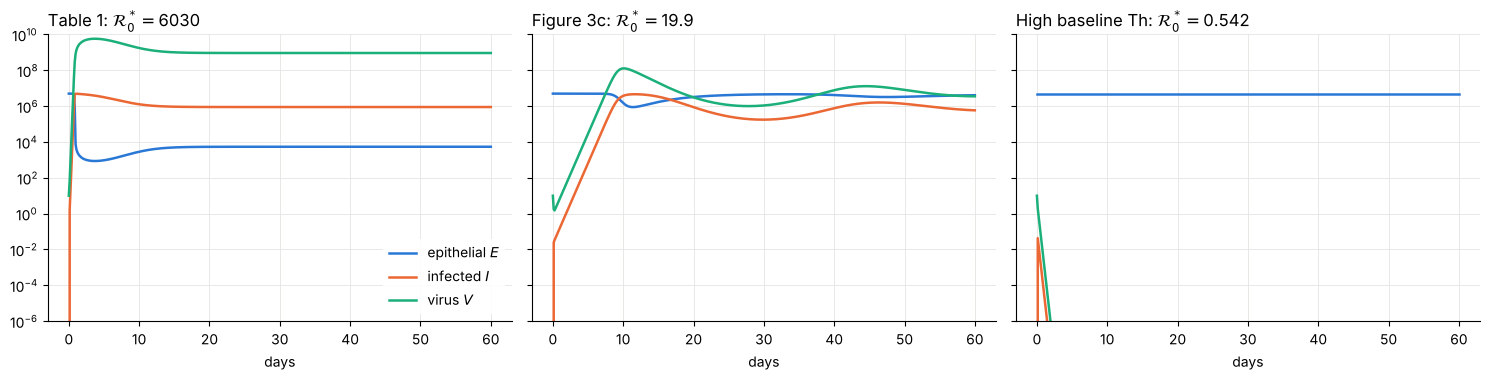

In [14]:
th = R0Model('''
    dE/dt  = lambda - d*E - kappa*E*V
    dI/dt  = kappa*E*V - alpha*I - beta*Th*I
    dV/dt  = nu*I - mu*V - tau*Th*V
    dTh/dt = b - c*Th + gamma*I*Th
''', infected=["I", "V"])

table1 = {"lambda": 5e5, "d": 0.1, "kappa": 1e-7, "alpha": 0.1, "beta": 1e-7, "nu": 995,
          "mu": 0.5, "tau": 1e-7, "b": 5e4, "c": 0.1, "gamma": 1e-7}
scenarios = {
    "Table 1": table1,
    "Figure 3c": dict(table1, **{"lambda": 1e6, "beta": 1.1e-7, "tau": 1e-4, "d": 0.2, "kappa": 1e-8, "b": 2e4}),
    "High baseline Th": dict(table1, b=3e7),
}

fig, axes = plt.subplots(1, 3, figsize=(15, 3.9), sharey=True)
for ax, (name, vals) in zip(axes, scenarios.items()):
    start = {"E": vals["lambda"] / vals["d"], "I": 0, "V": 10, "Th": vals["b"] / vals["c"]}
    r = th.simulate((0, 60), values=vals, initial=start)
    print(f"{name:<16} R0* = {r.R0:9.4f}   final V = {r.final()['V']:.3e}")
    r0_txt = f"{r.R0:.0f}" if r.R0 >= 100 else f"{r.R0:.3g}"
    r.plot(["E", "I", "V"], ax=ax, title=name + r": $\mathcal{R}_0^* = $" + r0_txt,
           logy=True, ylim=(1e-6, 1e10), xlabel="days", legend=(ax is axes[0]),
           labels={"E": "epithelial $E$", "I": "infected $I$", "V": "virus $V$"})
fig.savefig("outputs/06_Th_model_scenarios.png", dpi=200, bbox_inches="tight")

## 8. A DFE without closed form: the interferon, NK cell and macrophage loop

The model of notebook 04 has a DFE block that is not solved symbolically in time (`dfe_timeout`). `simulate()` uses the numerical DFE as initial condition. Here selected variables are plotted in separate panels, each with its own title. In this model the infection does not stimulate the innate loop, so $N$, $M$ and $F$ stay at their DFE value and are not plotted.

SimulationResult(1 run, R0 = 1.362, t in [0, 300]) | initial DFE of N, M, F: {'N': 5.3148, 'M': 5.6562, 'F': 2.1995}


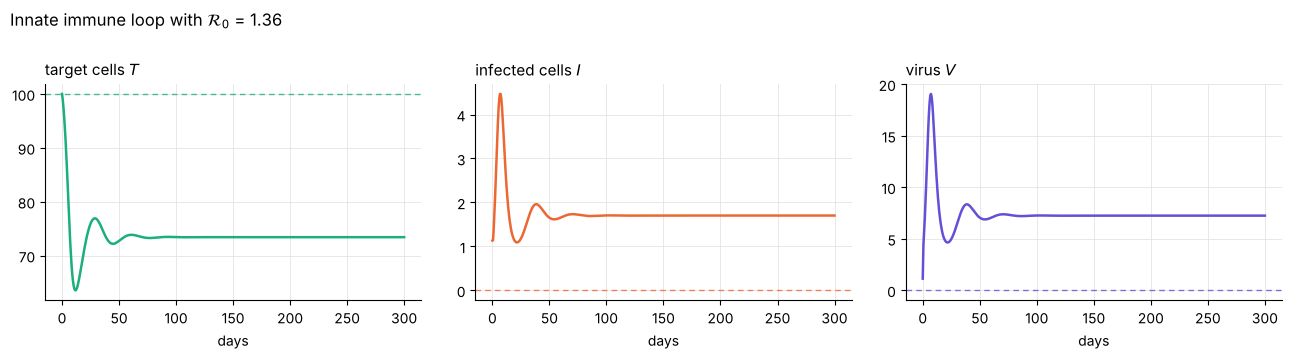

In [15]:
loop = '''
    dT/dt = s - d_T*T - beta*T*V
    dI/dt = beta*T*V - (delta + k_N*N)*I
    dV/dt = p*I - (c + k_M*M)*V
    dN/dt = a_N - d_N*N + h_N*F^2/(F^2 + K_F^2)
    dM/dt = a_M - d_M*M + h_M*N/(N + K_N)
    dF/dt = a_F - d_F*F + h_F*M/(M + K_M)
'''
with warnings.catch_warnings():
    warnings.simplefilter("ignore")      # dfe_timeout warning: the block {N, M, F} stays implicit
    model_loop = R0Model(loop, infected=["I", "V"], dfe_timeout=5)

v_loop = dict(s=10, d_T=0.1, beta=0.005, delta=0.5, k_N=0.2, p=20, c=3, k_M=0.3,
              a_N=1, d_N=0.5, h_N=2, K_F=1, a_M=1, d_M=0.4, h_M=1.5, K_N=1, a_F=0.5, d_F=1, h_F=2, K_M=1)
r = model_loop.simulate((0, 300), values=v_loop)
print(r, "| initial DFE of N, M, F:", {k: round(r.initial[k], 4) for k in "NMF"})
r.plot(["T", "I", "V"], subplots=True, ncols=3, figsize=(13, 3.6), xlabel="days",
       title=r"Innate immune loop with $\mathcal{R}_0$ = {R0}",
       titles={"T": "target cells $T$", "I": "infected cells $I$", "V": "virus $V$"},
       colors=[PALETTE[2], PALETTE[1], PALETTE[6]], show_dfe=True,
       save="outputs/06_immune_loop_panels.png");

Increasing the activation of NK cells by interferon ($h_N$) brings $\mathcal{R}_0$ below 1 and the virus is cleared:

SimulationResult(12 runs, R0 < 1 in 9, R0 > 1 in 3, t in [0, 300])


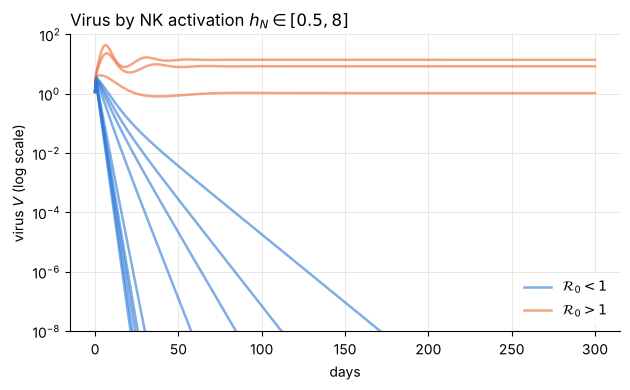

In [16]:
ensemble_loop = model_loop.simulate((0, 300), values={k: x for k, x in v_loop.items() if k != "h_N"},
                                    ranges={"h_N": (0.5, 8)}, sampling="uniform", n_runs=12, seed=4)
print(ensemble_loop)
ensemble_loop.plot("V", logy=True, ylim=(1e-8, 1e2), xlabel="days", ylabel="virus $V$ (log scale)",
                   title=r"Virus by NK activation $h_N \in [0.5, 8]$",
                   save="outputs/06_immune_loop_ensemble.png");

## 9. Vector-borne transmission: Ross-Macdonald

With humans $S_h, I_h, R_h$ and vectors $S_v, I_v$, $\mathcal{R}_0$ is the square root of the product of the human-to-vector and vector-to-human transmissions. We plot the prevalences $I_h/N_h$ and $I_v/N_v$, on a logarithmic scale, for three values of the biting rate $a$. With $\mathcal{R}_0 < 1$ prevalence decays from the first day. With $\mathcal{R}_0 > 1$ there is an outbreak; after the peak prevalence falls because the outbreak depletes the human susceptibles, which are replenished very slowly (life expectancy of 60 years). The endemic equilibrium, which exists because $\mathcal{R}_0 > 1$, is not reached in this two-year window.

R0 = sqrt(Lambda_v)*a*sqrt(b)*sqrt(c)/(sqrt(N_h)*mu_v*sqrt(mu_h + r))


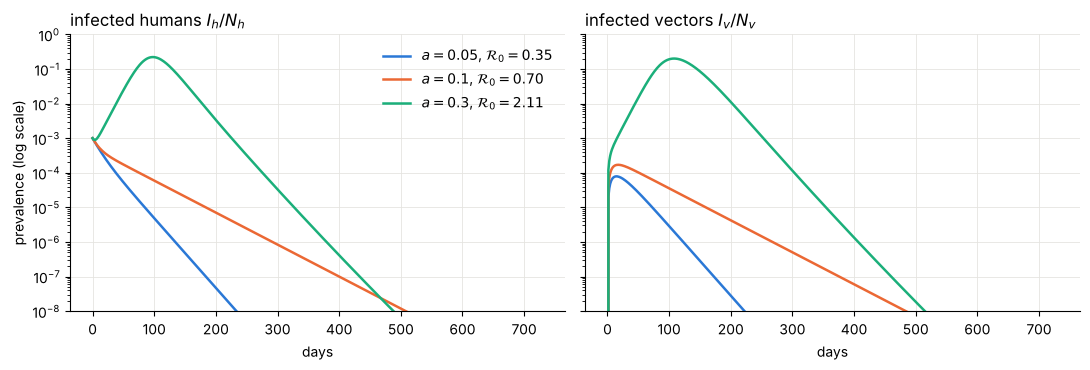

In [17]:
vector = R0Model('''
    dSh/dt = mu_h*N_h - a*b*Sh*Iv/N_h - mu_h*Sh
    dIh/dt = a*b*Sh*Iv/N_h - (r + mu_h)*Ih
    dRh/dt = r*Ih - mu_h*Rh
    dSv/dt = Lambda_v - a*c*Sv*Ih/N_h - mu_v*Sv
    dIv/dt = a*c*Sv*Ih/N_h - mu_v*Iv
''', infected=["Ih", "Iv"])
print("R0 =", vector.R0)

vv = dict(N_h=1000, mu_h=1 / (60 * 365), b=0.3, c=0.3, r=1 / 14, Lambda_v=200, mu_v=1 / 14)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for k, a in enumerate([0.05, 0.1, 0.3]):
    rv = vector.simulate((0, 730), values=dict(vv, a=a), initial={"Sh": 999, "Ih": 1, "Rh": 0, "Sv": 2800, "Iv": 0})
    lab = rf"$a = {a}$, $\mathcal{{R}}_0 = {rv.R0:.2f}$"
    axes[0].plot(rv.t, rv["Ih"] / vv["N_h"], color=PALETTE[k], linewidth=1.8, label=lab)
    axes[1].plot(rv.t, rv["Iv"] / (vv["Lambda_v"] / vv["mu_v"]), color=PALETTE[k], linewidth=1.8, label=lab)
for ax, txt in zip(axes, ["infected humans $I_h/N_h$", "infected vectors $I_v/N_v$"]):
    ax.set_title(txt, loc="left")
    ax.set_yscale("log")
    ax.set_ylim(1e-8, 1)
    ax.set_xlabel("days")
    ax.grid(True, color="#e5e4e0", linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("prevalence (log scale)")
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig("outputs/06_ross_macdonald.png", dpi=200, bbox_inches="tight")

## 10. The simulation data

`to_dataframe()` returns all simulations in long format (one row per time and simulation, with its $\mathcal{R}_0$), ready to export or analyze.

In [18]:
table = ensemble.to_dataframe()
table.to_csv("outputs/06_sir_ensemble.csv", index=False)
print(table.shape)
table.head()

(20000, 6)


,run,t,S,I,R,R0
0,0,0.000000,100.000000,1.000000,0.000000,0.772225
1,0,0.400802,99.823064,0.946540,0.191109,0.772225
2,0,0.801603,99.662847,0.895657,0.364465,0.772225
3,0,1.202405,99.518175,0.847270,0.521262,0.772225
4,0,1.603206,99.387944,0.801292,0.662634,0.772225


## Summary

| Case | What it shows |
|---|---|
| SIR with fixed $\beta$ | $\mathcal{R}_0 < 1$: returns to the DFE; $\mathcal{R}_0 > 1$: endemic equilibrium |
| Random parameters | `simulate()` without `values`, reproducible with `seed` |
| Ensemble of simulations | fixed and random parameters, colored by $\mathcal{R}_0$, phase plane |
| `R0_range` | only draws with $\mathcal{R}_0 > 1$ or $< 1$ |
| Sweep of $\beta$ | transcritical bifurcation at $\mathcal{R}_0 = 1$ |
| Near the threshold | slow convergence as $\mathcal{R}_0 \to 1$ |
| SEIR with vaccination | scenarios on the same axes; critical coverage $p_c = 1 - 1/\mathcal{R}_0$ |
| Within-host TIV | chronic infection versus viral clearance |
| Th model | scenarios of the paper and a high Th response with $\mathcal{R}_0^* < 1$ |
| Innate immune loop | DFE without closed form; one panel per variable |
| Ross-Macdonald | $\mathcal{R}_0$ as a square root; outbreak with $\mathcal{R}_0 > 1$ and decay with $\mathcal{R}_0 < 1$ |

All figures and the table are saved in the `outputs/` folder.